
# Exploratory Data Analysis (EDA)

## Toxic Comment and Hate Speech Detection

### 1. Project Overview
This project aims to detect toxic comments and hate speech in online text using Natural Language Processing (NLP) and Deep Learning techniques.

### 2. Dataset Description
The dataset is obtained from the Jigsaw Toxic Comment Classification Challenge on Kaggle.

Dataset Source:
https://www.kaggle.com/competitions/jigsaw-toxic-comment-classification-challenge/data

### 3. Dataset Labels
The dataset contains six target labels:

- toxic
- severe_toxic
- obscene
- threat
- insult
- identity_hate

### 4. Project Task
Multi-label Text Classification.

A single comment can belong to more than one toxicity category.

### 5. EDA Objectives
- Understand the dataset structure.
- Explore the number of samples and features.
- Identify missing values.
- Detect duplicate comments.
- Analyze target label distribution.
- Explore comment length and text characteristics.
- Visualize important patterns in the dataset.

### 6. Expected Outcome
Understand the dataset characteristics and identify potential data quality issues before preprocessing and model training.



## 2. Importing Libraries

In this section, we import the Python libraries required for Exploratory Data Analysis (EDA) and text analysis.

These libraries will help us manipulate the dataset, perform numerical operations, visualize data distributions, and analyze text content.

### Libraries Used

1. **Pandas:** Used for loading, manipulating, and analyzing structured data.
2. **NumPy:** Used for numerical operations and array manipulation.
3. **Matplotlib:** Used for creating data visualizations and charts.
4. **Seaborn:** Used for statistical data visualization.
5. **Regular Expressions (re):** Used for identifying and handling text patterns.
6. **Counter:** Used for counting the frequency of words and elements.

### Display Configuration

We also configure Pandas display settings to make dataframes easier to inspect and set Seaborn's visualization style for clearer charts.

### Expected Outcome

Successfully import all required libraries and prepare the Python environment for the next stages of data exploration.


In [1]:

# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text Analysis
import re
from collections import Counter

# Display Settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

# Visualization Style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!



## 3. Loading the Dataset

In this section, we load the datasets provided by the Jigsaw Toxic Comment Classification Challenge.

The dataset consists of four CSV files:

1. **train.csv:** Contains comments and their six toxicity labels.
2. **test.csv:** Contains comments without their target labels.
3. **test_labels.csv:** Contains the corresponding test labels.
4. **sample_submission.csv:** Provides the required submission format.

We use Pandas to load these files into DataFrames for further exploration and analysis.


In [3]:

# Define Dataset Paths

train_path = "../data/raw/train.csv"
test_path = "../data/raw/test.csv"
test_labels_path = "../data/raw/test_labels.csv"
submission_path = "../data/raw/sample_submission.csv"

# Load CSV Files

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
test_labels_df = pd.read_csv(test_labels_path)
submission_df = pd.read_csv(submission_path)

print("All datasets loaded successfully!")


All datasets loaded successfully!



### 4.1 Dataset Dimensions

In this subsection, we examine the dimensions of the four dataset files.

The shape of a DataFrame returns two values:

- **Rows:** The total number of records.
- **Columns:** The total number of features or attributes.

This helps us understand the size of each dataset before performing further analysis.


In [9]:
# Display Dataset Dimensions

datasets = {
    "Training Dataset": train_df,
    "Testing Dataset": test_df,
    "Test Labels": test_labels_df,
    "Submission Dataset": submission_df
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

Training Dataset: 159571 rows, 8 columns
Testing Dataset: 153164 rows, 2 columns
Test Labels: 153164 rows, 7 columns
Submission Dataset: 153164 rows, 7 columns



### 4.2 Dataset Columns

In this subsection, we identify the columns available in each dataset.

The training dataset contains the comment text and six target labels representing different types of toxic behavior.

Examining the columns helps us understand the structure of the data and identify the features required for our project.


In [10]:
# Display Column Names

print("Training Dataset Columns:")
print(train_df.columns.tolist())

print("\nTesting Dataset Columns:")
print(test_df.columns.tolist())

print("\nTest Labels Columns:")
print(test_labels_df.columns.tolist())

print("\nSubmission Dataset Columns:")
print(submission_df.columns.tolist())

Training Dataset Columns:
['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

Testing Dataset Columns:
['id', 'comment_text']

Test Labels Columns:
['id', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

Submission Dataset Columns:
['id', 'toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']



### 4.3 Dataset Information

In this subsection, we examine the training dataset using the `info()` method.

This method provides important information about the dataset, including:

- Number of rows and columns.
- Column names.
- Data types.
- Number of non-null values.
- Memory usage.

This helps us understand the data structure and identify potential data quality issues.


In [11]:
# Display Training Dataset Information

train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   id             159571 non-null  str  
 1   comment_text   159571 non-null  str  
 2   toxic          159571 non-null  int64
 3   severe_toxic   159571 non-null  int64
 4   obscene        159571 non-null  int64
 5   threat         159571 non-null  int64
 6   insult         159571 non-null  int64
 7   identity_hate  159571 non-null  int64
dtypes: int64(6), str(2)
memory usage: 72.2 MB



### 4.4 Dataset Preview

In this subsection, we display the first five rows of each dataset using the `head()` method.

This allows us to inspect the actual data, understand how comments and labels are stored, and become familiar with the dataset format.

We preview all four files to understand their contents and structure.


In [12]:
# Display First 5 Rows of Each Dataset

print("Training Dataset:")
display(train_df.head())

print("Testing Dataset:")
display(test_df.head())

print("Test Labels:")
display(test_labels_df.head())

print("Submission Dataset:")
display(submission_df.head())

Training Dataset:


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,"Explanation\nWhy the edits made under my username Hardcore Metallica Fan were reverted? They weren't vandalisms, just closure on some GAs after I ...",0,0,0,0,0,0
1,000103f0d9cfb60f,"D'aww! He matches this background colour I'm seemingly stuck with. Thanks. (talk) 21:51, January 11, 2016 (UTC)",0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It's just that this guy is constantly removing relevant information and talking to me through edits in...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on improvement - I wondered if the section statistics should be later on, or a subsection of """"types of...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember what page that's on?",0,0,0,0,0,0


Testing Dataset:


,id,comment_text
0,00001cee341fdb12,Yo bitch Ja Rule is more succesful then you'll ever be whats up with you and hating you sad mofuckas...i should bitch slap ur pethedic white faces...
1,0000247867823ef7,"== From RfC == \n\n The title is fine as it is, IMO."
2,00013b17ad220c46,""" \n\n == Sources == \n\n * Zawe Ashton on Lapland — / """
3,00017563c3f7919a,":If you have a look back at the source, the information I updated was the correct form. I can only guess the source hadn't updated. I shall update..."
4,00017695ad8997eb,I don't anonymously edit articles at all.


Test Labels:


,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,00001cee341fdb12,-1,-1,-1,-1,-1,-1
1,0000247867823ef7,-1,-1,-1,-1,-1,-1
2,00013b17ad220c46,-1,-1,-1,-1,-1,-1
3,00017563c3f7919a,-1,-1,-1,-1,-1,-1
4,00017695ad8997eb,-1,-1,-1,-1,-1,-1


Submission Dataset:


,id,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,00001cee341fdb12,0.5,0.5,0.5,0.5,0.5,0.5
1,0000247867823ef7,0.5,0.5,0.5,0.5,0.5,0.5
2,00013b17ad220c46,0.5,0.5,0.5,0.5,0.5,0.5
3,00017563c3f7919a,0.5,0.5,0.5,0.5,0.5,0.5
4,00017695ad8997eb,0.5,0.5,0.5,0.5,0.5,0.5



### 4.5 Missing Values Analysis

In this subsection, we check the training dataset for missing values.

Missing values occur when some records do not contain information in one or more columns.

We use the `isnull()` and `sum()` methods to calculate the number of missing values in each column.

This analysis helps us determine whether missing data needs to be handled during preprocessing.


In [13]:
# Check Missing Values in Training Dataset

missing_values = train_df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:")
print(missing_values.sum())

Missing Values in Each Column:
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

Total Missing Values:
0



### 4.6 Duplicate Records Analysis

In this subsection, we identify duplicate records and repeated comments in the training dataset.

We perform two checks:

1. **Duplicate Rows:** Detects rows that are identical across all columns.
2. **Duplicate Comments:** Detects repeated comment text, even if their labels are different.

Identifying duplicates is important because repeated data may affect the training process and model evaluation.

At this stage, we only identify duplicates without removing them.


In [14]:
# Check Duplicate Records

duplicate_rows = train_df.duplicated().sum()
duplicate_comments = train_df["comment_text"].duplicated().sum()

print("Duplicate Rows:", duplicate_rows)
print("Duplicate Comments:", duplicate_comments)

Duplicate Rows: 0
Duplicate Comments: 0



### 4.7 Classification Labels Distribution

In this subsection, we examine the distribution of the six toxicity labels in the training dataset.

The project includes the following target labels:

1. **toxic:** General toxic comments.
2. **severe_toxic:** Highly toxic comments.
3. **obscene:** Comments containing obscene language.
4. **threat:** Comments containing threats.
5. **insult:** Insulting or offensive comments.
6. **identity_hate:** Comments expressing hatred toward a particular identity.

Each label is binary, where:

- **0:** The comment does not belong to this category.
- **1:** The comment belongs to this category.

This analysis helps us understand the frequency of each category and identify potential class imbalance.


In [15]:
# Define Target Labels

target_columns = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

# Display Label Distribution

for label in target_columns:
    print(f"\n{label}:")
    print(train_df[label].value_counts().sort_index())


toxic:
toxic
0    144277
1     15294
Name: count, dtype: int64

severe_toxic:
severe_toxic
0    157976
1      1595
Name: count, dtype: int64

obscene:
obscene
0    151122
1      8449
Name: count, dtype: int64

threat:
threat
0    159093
1       478
Name: count, dtype: int64

insult:
insult
0    151694
1      7877
Name: count, dtype: int64

identity_hate:
identity_hate
0    158166
1      1405
Name: count, dtype: int64



### 4.8 Basic Text Statistics

In this subsection, we analyze the length of comments in the training dataset.

We calculate the number of characters in each comment and use descriptive statistics to understand the text length distribution.

The analysis includes:

- **Count:** Total number of comments.
- **Mean:** Average comment length.
- **Standard Deviation:** Variation in comment lengths.
- **Minimum:** Shortest comment length.
- **Maximum:** Longest comment length.
- **Quartiles:** Distribution of comment lengths.

Understanding text length helps us identify short and long comments and prepare for future text preprocessing and tokenization.


In [16]:
# Calculate Comment Length

train_df["comment_length"] = train_df["comment_text"].astype(str).apply(len)

# Display Text Length Statistics

print("Comment Length Statistics:")
print(train_df["comment_length"].describe())

Comment Length Statistics:
count    159571.000000
mean        394.073221
std         590.720282
min           6.000000
25%          96.000000
50%         205.000000
75%         435.000000
max        5000.000000
Name: comment_length, dtype: float64



### 5.1 Label Distribution Visualization

In this subsection, we visualize the distribution of the six toxicity labels in the training dataset.

We compare the number of positive (1) and negative (0) samples for each label using a grouped bar chart.

This visualization helps us:

- Compare the distribution of positive and negative samples.
- Identify class imbalance across different toxicity categories.
- Understand which toxicity categories have fewer positive samples.

The results will help us understand the challenges that may affect model training and evaluation.


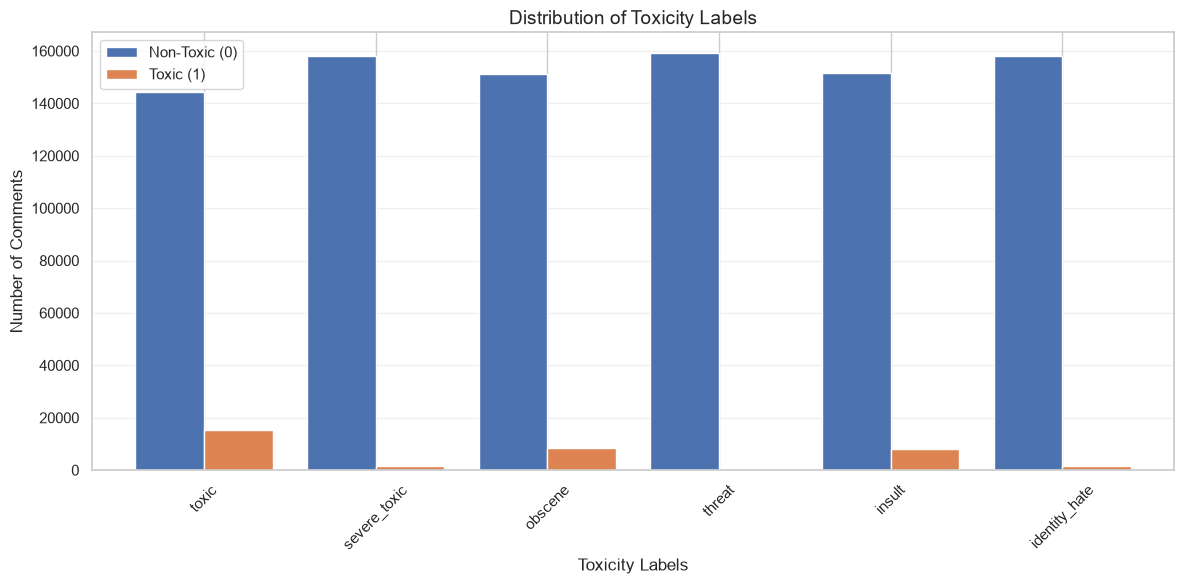

In [17]:
# Calculate Label Distribution

label_counts = train_df[target_columns].apply(
    pd.Series.value_counts
).T

label_counts = label_counts.fillna(0)

# Plot Label Distribution

label_counts.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Distribution of Toxicity Labels", fontsize=14)
plt.xlabel("Toxicity Labels", fontsize=12)
plt.ylabel("Number of Comments", fontsize=12)

plt.xticks(rotation=45)
plt.legend(["Non-Toxic (0)", "Toxic (1)"])

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 5.2 Comment Length Distribution

In this subsection, we visualize the distribution of comment lengths in the training dataset using a histogram.

The comment length represents the number of characters in each comment.

A histogram groups comment lengths into intervals (bins) and displays the frequency of comments within each interval.

This visualization helps us:

- Understand how comment lengths are distributed.
- Identify the most common comment length ranges.
- Detect unusually long comments.
- Understand the variation in text lengths before preprocessing and tokenization.

This analysis can help us make better decisions when preparing text data for NLP models.


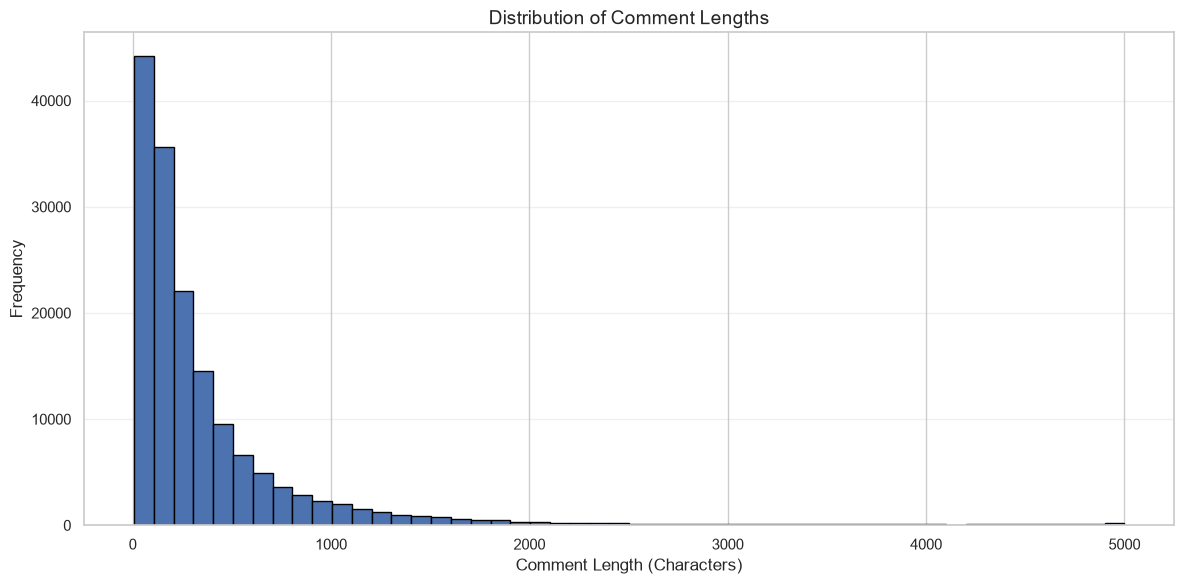

In [18]:
# Plot Comment Length Distribution

plt.figure(figsize=(12, 6))

plt.hist(
    train_df["comment_length"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Comment Lengths", fontsize=14)
plt.xlabel("Comment Length (Characters)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 5.3 Toxic vs Non-Toxic Comments

In this subsection, we analyze the distribution of toxic and non-toxic comments using the general `toxic` label.

We divide the comments into two categories:

- **Non-Toxic (0):** Comments with a toxic label of 0.
- **Toxic (1):** Comments with a toxic label of 1.

We calculate the number and percentage of comments in each category and visualize the results using a bar chart.

This analysis helps us:

- Understand the overall distribution of toxic and non-toxic comments.
- Compare the proportion of toxic comments to non-toxic comments.
- Identify the level of imbalance in the general toxicity classification.

This information provides a clearer understanding of the dataset before model training.


Toxic vs Non-Toxic Distribution:
Non-Toxic: 144,277 comments (90.42%)
Toxic: 15,294 comments (9.58%)


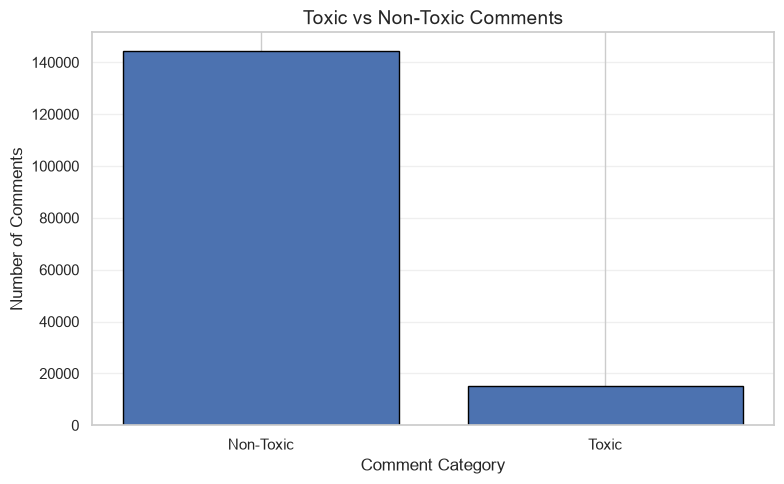

In [19]:
# Calculate Toxic and Non-Toxic Counts

toxic_counts = train_df["toxic"].value_counts().sort_index()

# Calculate Percentages

toxic_percentages = (
    toxic_counts / len(train_df) * 100
)

# Display Counts and Percentages

print("Toxic vs Non-Toxic Distribution:")

for label, count in toxic_counts.items():
    category = "Non-Toxic" if label == 0 else "Toxic"

    print(
        f"{category}: {count:,} comments "
        f"({toxic_percentages[label]:.2f}%)"
    )

# Plot Toxic vs Non-Toxic Distribution

plt.figure(figsize=(8, 5))

plt.bar(
    ["Non-Toxic", "Toxic"],
    toxic_counts.values,
    edgecolor="black"
)

plt.title("Toxic vs Non-Toxic Comments", fontsize=14)
plt.xlabel("Comment Category", fontsize=12)
plt.ylabel("Number of Comments", fontsize=12)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 5.4 EDA Summary & Key Findings

In this subsection, we summarize the main findings from the Exploratory Data Analysis (EDA).

We review the dataset structure, data quality, label distribution, and comment length statistics.

The main findings include:

1. **Dataset Size:** The training dataset contains 159,571 comments and eight columns.
2. **Data Quality:** No missing values or duplicate records were detected in the training dataset.
3. **Multi-Label Classification:** Each comment can belong to one or more of the six toxicity categories.
4. **Class Imbalance:** All six toxicity labels have significantly more negative samples than positive samples.
5. **Toxic Comments:** Approximately 9.58% of comments are labeled as toxic.
6. **Comment Length:** Comment lengths vary significantly, with a mean of approximately 394 characters and a maximum of 5,000 characters.
7. **Text Distribution:** The comment length distribution is right-skewed, with most comments being relatively short.

### Conclusion

The EDA findings reveal important characteristics of the dataset that must be considered during data preprocessing and model development.

In particular, class imbalance and variations in comment length are important challenges that may affect model performance.

These findings will guide the next stage of the project: Data Preprocessing.


In [22]:
# Generate EDA Summary

eda_summary = pd.DataFrame({
    "Metric": [
        "Training Dataset Rows",
        "Training Dataset Columns",
        "Missing Values",
        "Duplicate Rows",
        "Duplicate Comments",
        "Average Comment Length",
        "Median Comment Length",
        "Maximum Comment Length",
        "Toxic Comments",
        "Non-Toxic Comments"
    ],
    "Value": [
        len(train_df),
        len(train_df.columns.drop("comment_length")),
        train_df.isnull().sum().sum(),
        train_df.duplicated().sum(),
        train_df["comment_text"].duplicated().sum(),
        round(train_df["comment_length"].mean(), 2),
        train_df["comment_length"].median(),
        train_df["comment_length"].max(),
        int((train_df["toxic"] == 1).sum()),
        int((train_df["toxic"] == 0).sum())
    ]
})

# Display EDA Summary

display(eda_summary)

,Metric,Value
0,Training Dataset Rows,159571.00
1,Training Dataset Columns,8.00
2,Missing Values,0.00
3,Duplicate Rows,0.00
4,Duplicate Comments,0.00
5,Average Comment Length,394.07
6,Median Comment Length,205.00
7,Maximum Comment Length,5000.00
8,Toxic Comments,15294.00
9,Non-Toxic Comments,144277.00


In [21]:
# Generate Label Summary

label_summary = pd.DataFrame({
    "Label": target_columns,
    "Positive Samples": [
        int(train_df[label].sum())
        for label in target_columns
    ],
    "Negative Samples": [
        int((train_df[label] == 0).sum())
        for label in target_columns
    ],
    "Positive Percentage (%)": [
        round(train_df[label].mean() * 100, 2)
        for label in target_columns
    ]
})

# Display Label Summary

display(label_summary)

,Label,Positive Samples,Negative Samples,Positive Percentage (%)
0,toxic,15294,144277,9.58
1,severe_toxic,1595,157976,1.00
2,obscene,8449,151122,5.29
3,threat,478,159093,0.30
4,insult,7877,151694,4.94
5,identity_hate,1405,158166,0.88
